In [1]:
import os
import glob
from collections import defaultdict
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import laspy

import tensorflow as tf
from tensorflow.keras import layers, models


from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

# -- 1) Reproducibility seeds --
np.random.seed(42)
tf.random.set_seed(42)

# -- 2) Parameters --
FOLDER_PATH = "C:/Users/flori/Desktop/pa-1_data/training"
N_POINTS    = 1024
BLOCK_SIZE  = 50.0  # in meters
BATCH_SIZE  = 64

# -- 3) Locate and sort LAZ files --
file_paths = sorted(glob.glob(os.path.join(FOLDER_PATH, "*.laz")))
print(f"Found {len(file_paths)} files for preprocessing.")

# -- 4) Build global label map (excluding class 7) --
all_raw_labels = []
for path in file_paths:
    las = laspy.read(path)
    all_raw_labels.extend(np.unique(las.classification))
unique_labels = np.unique(all_raw_labels)
unique_labels = unique_labels[unique_labels != 7]
label_map = {raw: idx for idx, raw in enumerate(unique_labels)}
NUM_CLASSES = len(label_map)
print("Label map:", label_map)

# -- 5) Define tiling function --
def tile_pointclouds(X_all, y_all, coords_all, n_points, block_size, padding=True):
    x_min, y_min = coords_all[:,0].min(), coords_all[:,1].min()
    x_max, y_max = coords_all[:,0].max(), coords_all[:,1].max()
    x_edges = np.arange(x_min, x_max, block_size)
    y_edges = np.arange(y_min, y_max, block_size)
    X_list, y_list = [], []
    for xi in x_edges:
        for yi in y_edges:
            mask = (
                (coords_all[:,0] >= xi) & (coords_all[:,0] < xi+block_size) &
                (coords_all[:,1] >= yi) & (coords_all[:,1] < yi+block_size)
            )
            idx = np.where(mask)[0]
            if idx.size == 0:
                continue
            if idx.size >= n_points:
                chosen = np.random.choice(idx, n_points, replace=False)
            else:
                if not padding:
                    continue
                pad_idx = np.random.choice(idx, n_points - idx.size, replace=True)
                chosen = np.concatenate([idx, pad_idx])
            X_list.append(X_all[chosen])
            y_list.append(y_all[chosen])
    if not X_list:
        raise RuntimeError("No blocks created; check block_size/coords.")
    return np.stack(X_list), np.stack(y_list)

# -- 6) Preprocess each file, tile, center, scale & accumulate blocks --
all_X_blocks = []
all_y_blocks = []
for path in file_paths:
    # Read raw LAS
    las = laspy.read(path)
    raw_labels = las.classification.astype(int)
    # Feature extraction
    ground_z = np.min(las.z)
    X = np.vstack([
        las.x, las.y, las.z,
        las.intensity,
        las.return_number,
        las.number_of_returns,
        las.z - ground_z,
        las.scan_angle
    ]).T.astype(np.float32)
    # Mask out class 7, map labels
    mask = (raw_labels != 7)
    X = X[mask]
    y = np.array([label_map[r] for r in raw_labels[mask]], dtype=np.int64)
    # Tile into blocks
    coords = X[:, :2]  # raw x,y in meters
    X_blocks, y_blocks = tile_pointclouds(X, y, coords,
                                          n_points=N_POINTS,
                                          block_size=BLOCK_SIZE,
                                          padding=True)
    # Center each block in x,y,z
    for b in range(X_blocks.shape[0]):
        cent = X_blocks[b, :, :3].mean(axis=0)
        X_blocks[b, :, :3] -= cent
    # Scale non-spatial channels (dims 3..end)
    non_sp = X_blocks[:, :, 3:]
    M, P, K = non_sp.shape
    flat = non_sp.reshape(-1, K)
    scaler = StandardScaler()
    flat_scaled = scaler.fit_transform(flat)
    X_blocks[:, :, 3:] = flat_scaled.reshape(M, P, K)
    # Accumulate
    all_X_blocks.append(X_blocks)
    all_y_blocks.append(y_blocks)
    print(f"Processed {path}: generated {X_blocks.shape[0]} blocks.")

# Concatenate all blocks
X_pointcloud = np.concatenate(all_X_blocks, axis=0)
y_pointcloud = np.concatenate(all_y_blocks, axis=0)
print("Total blocks:", X_pointcloud.shape[0])

# -- 7) Train/test split --
X_train, X_test, y_train, y_test = train_test_split(
    X_pointcloud, y_pointcloud, test_size=0.2, random_state=42
)

# -- 8) Class weights for balanced training --
y_train_flat = y_train.flatten()
classes = np.arange(NUM_CLASSES)
cw = compute_class_weight("balanced", classes=classes, y=y_train_flat)
class_weights = tf.constant(cw, dtype=tf.float32)

def attach_weights(X, y):
    w = tf.gather(class_weights, tf.cast(y, tf.int32))
    return X, y, w


Found 14 files for preprocessing.
Label map: {np.uint8(1): 0, np.uint8(2): 1, np.uint8(3): 2, np.uint8(4): 3, np.uint8(5): 4, np.uint8(6): 5, np.uint8(15): 6, np.uint8(17): 7}
Processed C:/Users/flori/Desktop/pa-1_data/training\2671500_1251000.laz: generated 100 blocks.
Processed C:/Users/flori/Desktop/pa-1_data/training\2671500_1252000.laz: generated 100 blocks.
Processed C:/Users/flori/Desktop/pa-1_data/training\2672500_1252000.laz: generated 100 blocks.
Processed C:/Users/flori/Desktop/pa-1_data/training\2673000_1251500.laz: generated 100 blocks.
Processed C:/Users/flori/Desktop/pa-1_data/training\2679500_1249500.laz: generated 100 blocks.
Processed C:/Users/flori/Desktop/pa-1_data/training\2680000_1249000.laz: generated 100 blocks.
Processed C:/Users/flori/Desktop/pa-1_data/training\2680500_1249500.laz: generated 100 blocks.
Processed C:/Users/flori/Desktop/pa-1_data/training\2687000_1250000.laz: generated 100 blocks.
Processed C:/Users/flori/Desktop/pa-1_data/training\2687500_1251

In [2]:
# -- 9) Data augmentation functions --
def random_rotate_pointcloud(batch):
    batch_size = tf.shape(batch)[0]
    angles = tf.random.uniform((batch_size,), 0, 2*np.pi)
    cosA = tf.cos(angles); sinA = tf.sin(angles)
    zeros = tf.zeros_like(cosA); ones = tf.ones_like(cosA)
    R = tf.stack([
        tf.stack([cosA, -sinA, zeros], axis=1),
        tf.stack([sinA,  cosA, zeros], axis=1),
        tf.stack([zeros, zeros, ones], axis=1)
    ], axis=1)
    xyz = batch[:, :, :3]
    rest = batch[:, :, 3:]
    xyz_rot = tf.matmul(xyz, R)
    return tf.concat([xyz_rot, rest], axis=-1)

def jitter_pointcloud(batch, sigma=0.01, clip=0.05):
    jitter = tf.clip_by_value(sigma * tf.random.normal(tf.shape(batch)), -clip, clip)
    return batch + jitter

def augment_fn(X, y, w):
    X = random_rotate_pointcloud(X)
    X = jitter_pointcloud(X)
    return X, y, w

In [3]:
# --- 10) Build tf.data datasets ---
# 10.1 Base datasets
base_train = tf.data.Dataset.from_tensor_slices((X_train, y_train))
base_test  = tf.data.Dataset.from_tensor_slices((X_test,  y_test))

# 10.2 Training pipeline: shuffle → batch → attach weights → augment → prefetch
train_ds = (
    base_train
    .shuffle(buffer_size=2048, seed=42)
    .batch(BATCH_SIZE)
    .map(attach_weights, num_parallel_calls=tf.data.AUTOTUNE)  # now yields (X, y, w)
    .map(augment_fn,     num_parallel_calls=tf.data.AUTOTUNE)  # augment_fn accepts (X, y, w)
    .prefetch(tf.data.AUTOTUNE)
)

# 10.3 Validation pipeline: batch → attach weights → prefetch (no augment)
test_ds = (
    base_test
    .batch(BATCH_SIZE)
    .map(attach_weights, num_parallel_calls=tf.data.AUTOTUNE)  # yields (X, y, w)
    .prefetch(tf.data.AUTOTUNE)
)

print("Preprocessing and dataset creation complete.")

Preprocessing and dataset creation complete.


In [4]:
class OrthogonalRegularizer(layers.Layer):
    """Adds orthogonality regularization for a (batch, k, k) matrix."""
    def __init__(self, reg_weight=1e-3, **kwargs):
        super().__init__(**kwargs)
        self.reg_weight = reg_weight

    def call(self, matrix):
        # matrix: (batch, k, k)
        # compute A * A^T
        aat = tf.matmul(matrix, tf.transpose(matrix, perm=[0, 2, 1]))
        # identity (k, k) where k = matrix.shape[-1]
        k = tf.shape(matrix)[1]
        I = tf.eye(k, dtype=matrix.dtype)
        # loss = mean squared Frobenius norm of (A A^T - I)
        loss = tf.reduce_mean(tf.square(aat - I))
        self.add_loss(self.reg_weight * loss)
        return matrix

def tnet(inputs, k, name):
    x = layers.Conv1D(64, 1, use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(128, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(1024, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.GlobalMaxPooling1D()(x)
    x = layers.Dense(512, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dense(256, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    # initialize to identity bias
    bias_init = tf.keras.initializers.Constant(np.eye(k).flatten())
    x = layers.Dense(
        k * k,
        kernel_initializer='zeros',
        bias_initializer=bias_init,
        name=f"{name}_fc_transform"
    )(x)
    # reshape to (k, k)
    x = layers.Reshape((k, k), name=f"{name}_reshape")(x)
    # apply orthogonal regularization
    return OrthogonalRegularizer(name=f"{name}_orthoreg")(x)

def build_pointnet_model(num_points, num_features, num_classes):
    inputs = tf.keras.Input(shape=(num_points, num_features))

    # Input T-Net
    input_transform = tnet(inputs, num_features, name="input_tnet")
    x = layers.Lambda(lambda args: tf.matmul(args[0], args[1]))(
        [inputs, input_transform])

    # Per-point MLP
    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Feature T-Net
    feature_transform = tnet(x, 64, name="feature_tnet")
    x = layers.Lambda(lambda args: tf.matmul(args[0], args[1]))(
        [x, feature_transform])

    # Deeper per-point MLP
    x = layers.Conv1D(64, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(128, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(1024, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # Global feature
    global_feat = layers.GlobalMaxPooling1D()(x)

    # Segmentation head
    global_feat_repeated = layers.RepeatVector(num_points)(global_feat)
    concat = layers.Concatenate()([x, global_feat_repeated])

    x = layers.Conv1D(512, 1, use_bias=False)(concat)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(256, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv1D(128, 1, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Conv1D(num_classes, 1, activation='softmax')(x)

    return models.Model(inputs=inputs, outputs=outputs, name="PointNet_Segmentation")


In [8]:
NUM_CLASSES = len(np.unique(y_pointcloud))
model = build_pointnet_model(num_points=N_POINTS, num_features=X_pointcloud.shape[2], num_classes=NUM_CLASSES)

model.summary()


model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(5e-4),
    metrics=['accuracy']
)


Model: "PointNet_Segmentation"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 1024, 8)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_30 (Conv1D)  │ (None, 1024, 64)  │        512 │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024, 64)  │        256 │ conv1d_30[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_36 (ReLU)     │ (None, 1024, 64)  │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_31 (Conv1D)  │ (None, 1024, 128) │      8,192 │ re_lu_36[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024, 128) │        512 │ conv1d_31[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_37 (ReLU)     │ (None, 1024, 128) │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_32 (Conv1D)  │ (None, 1024,      │    131,072 │ re_lu_37[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1024,      │      4,096 │ conv1d_32[0][0]   │
│ (BatchNormalizatio… │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_38 (ReLU)     │ (None, 1024,      │          0 │ batch_normalizat… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 1024)      │          0 │ re_lu_38[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 512)       │    524,288 │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense_8[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_39 (ReLU)     │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 256)       │    131,072 │ re_lu_39[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_9[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_40 (ReLU)     │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_tnet_fc_tran… │ (None, 64)        │     16,448 │ re_lu_40[0][0]    │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_tnet_reshape  │ (None, 8, 8)      │          0 │ input_tnet_fc_tr… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 4,049,224 (15.45 MB)

 Trainable params: 4,036,808 (15.40 MB)

 Non-trainable params: 12,416 (48.50 KB)

In [9]:
# define callbacks
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-6,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=100,
    callbacks=[reduce_lr, early_stop]
)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 81s 4s/step - accuracy: 0.1584 - loss: 2.2762 - val_accuracy: 0.1266 - val_loss: 2.0675 - learning_rate: 5.0000e-04
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 76s 4s/step - accuracy: 0.3555 - loss: 1.8451 - val_accuracy: 0.6191 - val_loss: 2.0473 - learning_rate: 5.0000e-04
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 80s 4s/step - accuracy: 0.4465 - loss: 1.5313 - val_accuracy: 0.6142 - val_loss: 2.0310 - learning_rate: 5.0000e-04
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 78s 4s/step - accuracy: 0.4625 - loss: 1.4687 - val_accuracy: 0.6175 - val_loss: 2.0875 - learning_rate: 5.0000e-04
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 78s 4s/step - accuracy: 0.4774 - loss: 1.3526 - val_accuracy: 0.6309 - val_loss: 1.9873 - learning_rate: 5.0000e-04
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 79s 4s/step - accuracy: 0.5170 - loss: 1.3110 - val_accuracy: 0.6076 - val_loss: 1.8555 - learning_rate: 5.0000e-04
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 77s 4s/step - accuracy: 0.5177 

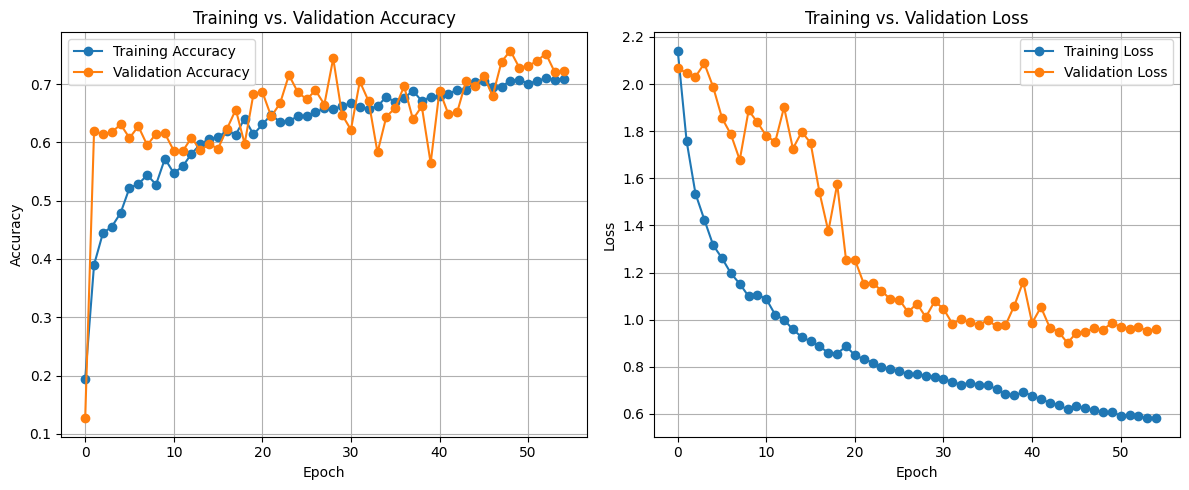

In [10]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.title('Training vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.title('Training vs. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [11]:
# Predict on test set
y_pred = model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=-1)

# Flatten for evaluation
y_true_flat = y_test.flatten()
y_pred_flat = y_pred_labels.flatten()

print("Accuracy:", accuracy_score(y_true_flat, y_pred_flat))
print(classification_report(y_true_flat, y_pred_flat))


9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 344ms/step
Accuracy: 0.6963692801339286
              precision    recall  f1-score   support

           0       0.24      0.49      0.32      6906
           1       0.96      0.71      0.82    175788
           2       0.05      0.46      0.08      4302
           3       0.37      0.68      0.48      9220
           4       0.93      0.78      0.85     30612
           5       0.95      0.64      0.77     55510
           6       0.07      0.81      0.12       334
           7       0.19      0.76      0.30      4048

    accuracy                           0.70    286720
   macro avg       0.47      0.67      0.47    286720
weighted avg       0.90      0.70      0.77    286720



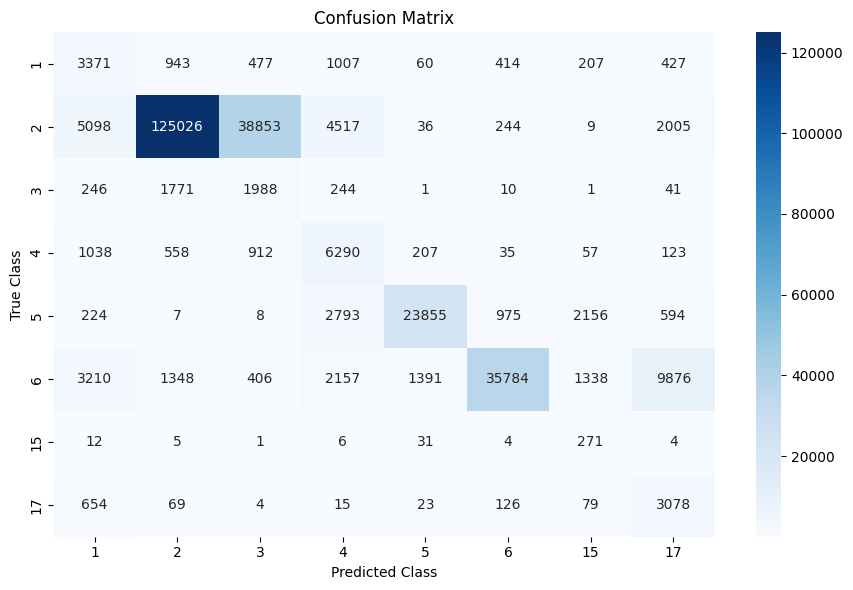

In [12]:
# Flatten labels
y_true = y_test.flatten()
y_pred_flat = y_pred_labels.flatten()

# Get inverse label map for display
inv_label_map = {v: k for k, v in label_map.items()}
labels = sorted(inv_label_map.keys())

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred_flat, labels=labels)

# Plot
plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"{inv_label_map[i]}" for i in labels],
            yticklabels=[f"{inv_label_map[i]}" for i in labels])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

### Deploy

In [14]:
def load_city_blocks(
    municipality_name: str,
    base_folder: str,
    N_POINTS: int,
    scaler: StandardScaler,
    label_map: dict,
    block_size: float = 50.0
):
    """
    Reads all .laz in base_folder/municipality_name, extracts features and labels,
    tiles into spatial blocks of N_POINTS, centers and scales them exactly
    as in training.

    Returns:
        X_test: np.array, shape (total_blocks, N_POINTS, n_features)
        y_test: np.array, shape (total_blocks, N_POINTS)
    """
    city_folder = os.path.join(base_folder, municipality_name)
    file_paths = sorted(glob.glob(os.path.join(city_folder, "*.laz")))
    print(f"Found {len(file_paths)} files in {municipality_name}")

    all_blocks = []
    all_labels = []
    for path in file_paths:
        las = laspy.read(path)
        # feature extraction
        ground_h = np.min(las.z)
        feats = np.vstack([
            las.x, las.y, las.z,
            las.intensity,
            las.return_number,
            las.number_of_returns,
            las.z - ground_h,
            las.scan_angle
        ]).T.astype(np.float32)
        raw_labels = las.classification.astype(int)
        # map & filter labels
        mask = (raw_labels != 7)
        feats = feats[mask]
        y_raw = raw_labels[mask]
        y_mapped = np.array([label_map[c] for c in y_raw], dtype=np.int32)

        if feats.shape[0] < N_POINTS:
            continue

        # tile spatially
        coords = feats[:, :2]
        X_blocks, y_blocks = tile_pointclouds(
            X_all=feats,
            y_all=y_mapped,
            coords_all=coords,
            n_points=N_POINTS,
            block_size=block_size,
            padding=True
        )

        # center each block in x,y,z
        for b in range(X_blocks.shape[0]):
            cent = X_blocks[b, :, :3].mean(axis=0)
            X_blocks[b, :, :3] -= cent

        # scale non-spatial dims
        M, P, F = X_blocks.shape
        non_sp = X_blocks[:, :, 3:].reshape(-1, F-3)
        non_sp_scaled = scaler.transform(non_sp)
        X_blocks[:, :, 3:] = non_sp_scaled.reshape(M, P, F-3)

        all_blocks.append(X_blocks)
        all_labels.append(y_blocks)
        print(f"  -> {os.path.basename(path)}: {X_blocks.shape[0]} blocks")

    if not all_blocks:
        print("No blocks found.")
        return np.empty((0, N_POINTS, feats.shape[1])), np.empty((0, N_POINTS), dtype=int)

    X_test = np.concatenate(all_blocks, axis=0)
    y_test = np.concatenate(all_labels, axis=0)
    print(f"Total test blocks: {X_test.shape[0]}")
    return X_test, y_test

def evaluate_city(municipality_name, X_test, y_test, model, label_map):
    """
    Predicts on X_test, computes metrics, and plots confusion matrix.
    """
    if X_test.size == 0:
        print(f"No test blocks for {municipality_name}.")
        return

    # 1) Prediction
    y_pred_probs = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=-1)

    # 2) Flatten and report
    y_true_flat = y_test.flatten()
    y_pred_flat = y_pred.flatten()

    print(f"\n=== Results for {municipality_name} ===")
    from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
    acc = accuracy_score(y_true_flat, y_pred_flat)
    print(f"Accuracy: {acc:.4f}\n")
    print("Classification Report:")
    print(classification_report(y_true_flat, y_pred_flat, digits=4))

    # 3) Confusion matrix
    inv_map = {v: k for k, v in label_map.items()}
    labels = sorted(inv_map.keys())
    cm = confusion_matrix(y_true_flat, y_pred_flat, labels=labels)

    import matplotlib.pyplot as plt
    import seaborn as sns
    plt.figure(figsize=(8,6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=[inv_map[i] for i in labels],
                yticklabels=[inv_map[i] for i in labels])
    plt.title(f"Confusion Matrix – {municipality_name}")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

Found 18 files in Dietikon
  -> 2671000_1251500_cropped.laz: 6 blocks
  -> 2671500_1251000_cropped.laz: 19 blocks
  -> 2671500_1251500_cropped.laz: 98 blocks
  -> 2671500_1252000_cropped.laz: 73 blocks
  -> 2671500_1252500_cropped.laz: 16 blocks
  -> 2672000_1250500_cropped.laz: 6 blocks
  -> 2672000_1251000_cropped.laz: 25 blocks
  -> 2672000_1251500_cropped.laz: 100 blocks
  -> 2672000_1252000_cropped.laz: 100 blocks
  -> 2672000_1252500_cropped.laz: 56 blocks
  -> 2672500_1250500_cropped.laz: 87 blocks
  -> 2672500_1251000_cropped.laz: 82 blocks
  -> 2672500_1251500_cropped.laz: 74 blocks
  -> 2672500_1252000_cropped.laz: 41 blocks
  -> 2672500_1252500_cropped.laz: 3 blocks
  -> 2673000_1250500_cropped.laz: 18 blocks
  -> 2673000_1251000_cropped.laz: 39 blocks
  -> 2673000_1251500_cropped.laz: 14 blocks
Total test blocks: 857

=== Results for Dietikon ===
Accuracy: 0.7490

Classification Report:
              precision    recall  f1-score   support

           0     0.2170    0.5810

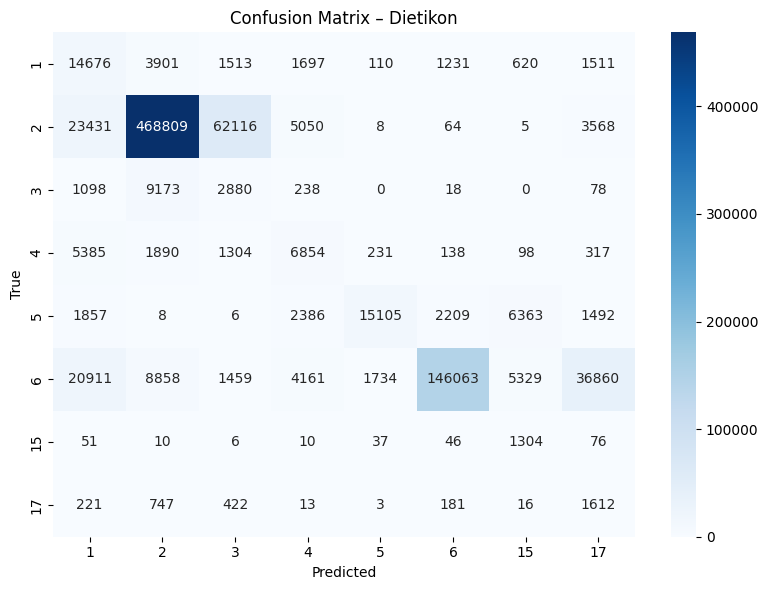

In [16]:
X_test, y_test = load_city_blocks(
    municipality_name="Dietikon",
    base_folder=r"C:/Users/flori/Desktop/pa-1_data/clipped_files",
    N_POINTS=1024,
    scaler=scaler,
    label_map=label_map
)

evaluate_city(
    municipality_name="Dietikon",
    X_test=X_test,
    y_test=y_test,
    model=model,
    label_map=label_map
)